# Figure 1 · Representative shortcut graphs

Maria Marina and Alexander Panchenko, *Structural Signatures of Correct Mathematical Reasoning Traces*, MathNLP 2026. The original case-study notebook chose two majority-error repairs and one structural drift using the three-prefix selector. The two drift panels use consecutive sampling budgets for the same question. [Published figure and caption, p. 195](https://aclanthology.org/2026.mathnlp-main.15.pdf)

Run all cells from the repository root or its `notebooks` directory after installing `.[notebook]`. The six graphs are rebuilt from the saved precedence counts. At the end, the notebook exports a PNG and a vector PDF to `docs/assets/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display

from structural_signatures.config import PRESETS
from structural_signatures.graphs import most_cross_linked, shortcuts

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/figure1/panels.json").exists())
inputs = root / "data/figure1"
panels = pd.DataFrame(json.loads((inputs / "panels.json").read_text()))
keys = ["id", "sample_size", "answer"]
types = {"id": str, "answer": str}
answers = pd.read_csv(inputs / "answers.csv", dtype=types)
precedence = pd.read_csv(inputs / "precedence.csv", dtype=types)
predictions = pd.read_csv(root / "data/reference/w3_predictions.csv.gz",
                          dtype={"id": str, "predicted_answer": str, "majority_answer": str},
                          keep_default_na=False).set_index(["id", "sample_size"])
config = PRESETS["historical_w3"]
pd.set_option("display.max_colwidth", 70)
layout = pd.read_csv(inputs / "layout.csv")
printed_edges = pd.read_csv(inputs / "printed_edges.csv")

## Recover the six components

A shortcut needs at least three co-occurrences, at least 80% agreement on the dominant order, and both a direct and an expanded instance in that direction. For each candidate, select the weakly connected component with the greatest cycle rank. A component with $E$ distinct undirected edges and $V$ checkpoints contributes $E-V+1$ excess edges.

The graph labels show the candidate’s **current** frequency and excess. The selected answer comes from its **trailing** score. Each displayed choice is checked against the archived prediction for that question and prefix.

In [2]:
eligible = shortcuts(precedence, config)
candidates = answers.set_index(keys, verify_integrity=True)
graphs = []
metrics = []

for panel in panels.itertuples(index=False):
    key = (panel.id, panel.sample_size, panel.answer)
    candidate = candidates.loc[key]
    saved = predictions.loc[(panel.id, panel.sample_size)]
    majority = panel.role == "Majority"
    chosen = saved.majority_answer if majority else saved.predicted_answer
    outcome = saved.majority_correct if majority else saved.prediction_correct
    assert (chosen, bool(outcome)) == (panel.answer, panel.correct)
    assert (int(candidate.raw_count), bool(candidate.is_correct_answer)) == (panel.raw_count, panel.correct)
    rows = eligible[(eligible.id == panel.id) & (eligible.sample_size == panel.sample_size)
                    & (eligible.answer == panel.answer)]
    graph, mu = most_cross_linked(zip(rows.from_community, rows.to_community))
    graphs.append(graph)
    metrics.append(dict(case=panel.case, role=panel.role, id=panel.id, k=panel.sample_size,
                        answer=panel.answer, frequency=int(candidate.raw_count),
                        vertices=len(graph), edges=graph.to_undirected().number_of_edges(),
                        excess=mu, static_score=mu / candidate.raw_count))

table = pd.DataFrame(metrics)
published = [(6, 4), (7, 0), (8, 9), (12, 7), (12, 3), (10, 4)]
assert list(zip(table.frequency, table.excess)) == published
display(table.round({"static_score": 3}))

,case,role,id,k,answer,frequency,vertices,edges,excess,static_score
0,Early repair,Structural,315,25,41,6,7,10,4,0.667
1,Early repair,Majority,315,25,1,7,6,5,0,0.000
2,Late repair,Structural,80,78,501,8,9,17,9,1.125
3,Late repair,Majority,80,78,499,12,14,20,7,0.583
4,Structural drift,Previous,435,40,"(-\infty, 2) \cup (3, \infty)",12,7,9,3,0.250
5,Structural drift,Current,435,41,"(-\infty, 2] \cup [3, \infty)",10,8,11,4,0.400


## Rebuild the printed panels

The colors and positions below come from the vector artwork on page 195. Each arrow still comes from the saved precedence counts. For each panel, the code checks the endpoints and direction of every recovered edge against the printed arrows, then checks that the ordinary edges span a tree and that the purple count equals the computed excess. This preserves the particular tree that the authors illustrated. To explore another layout, change `layout_mode` to `"spring"`.

In [3]:
CORRECT, WRONG, EXCESS = "#1b9e77", "#d95f02", "#7b1fa2"

layout_mode = "published"

def draw_panel(ax, graph, panel, row, number):
    topology = nx.Graph()
    topology.add_nodes_from(graph.nodes)
    topology.add_edges_from(graph.edges)
    ink = printed_edges[printed_edges.panel == number]
    printed = {(u, v) for u, v in zip(ink.from_community, ink.to_community)}
    assert set(graph.edges) == printed
    extra = list(ink.loc[ink.highlighted, ["from_community","to_community"]].itertuples(index=False, name=None))
    backbone = list(ink.loc[~ink.highlighted, ["from_community","to_community"]].itertuples(index=False, name=None))
    tree = nx.Graph()
    tree.add_nodes_from(graph)
    tree.add_edges_from(backbone)
    assert nx.is_tree(tree) and len(extra) == row.excess
    if layout_mode == "published":
        positions = layout[layout.panel == number]
        pos = {point.node: (point.x, point.y) for point in positions.itertuples()}
        assert set(pos) == set(graph)
    else:
        pos = nx.spring_layout(topology, seed=17, k=1.1)
    color = CORRECT if panel.correct else WRONG
    titles = {"Previous": r"$k-1$", "Current": r"$k$"}
    title = titles.get(panel.role, panel.role) + (" ✓" if panel.correct else " ✗")
    ax.set_title(title, color=color, fontsize=16, fontweight="bold", pad=5)
    for edges, edge_color, width, radius, arrow_size in [
        (backbone, color, 1.25, 0.04, 12), (extra, EXCESS, 3.2, 0.08, 15),
    ]:
        nx.draw_networkx_edges(graph, pos, ax=ax, edgelist=edges,
                               node_size=255, edge_color=edge_color, width=width,
                               alpha=1 if edge_color == EXCESS else 0.65,
                               arrowsize=arrow_size, connectionstyle=f"arc3,rad={radius}")
    nx.draw_networkx_nodes(graph, pos, ax=ax, node_color="white", edgecolors=color,
                           node_size=255, linewidths=1.7)
    nx.draw_networkx_labels(graph, pos, ax=ax, labels={n: f"C{int(n)}" for n in graph},
                            font_size=8.3)
    ax.text(0.5, -0.04, f"Freq={row.frequency}   Excess={row.excess}",
            transform=ax.transAxes, ha="center", va="top", fontsize=13)
    if layout_mode == "published":
        ax.set(xlim=(0, 1), ylim=(0, 1))
    else:
        ax.margins(0.15)
    ax.set_axis_off()

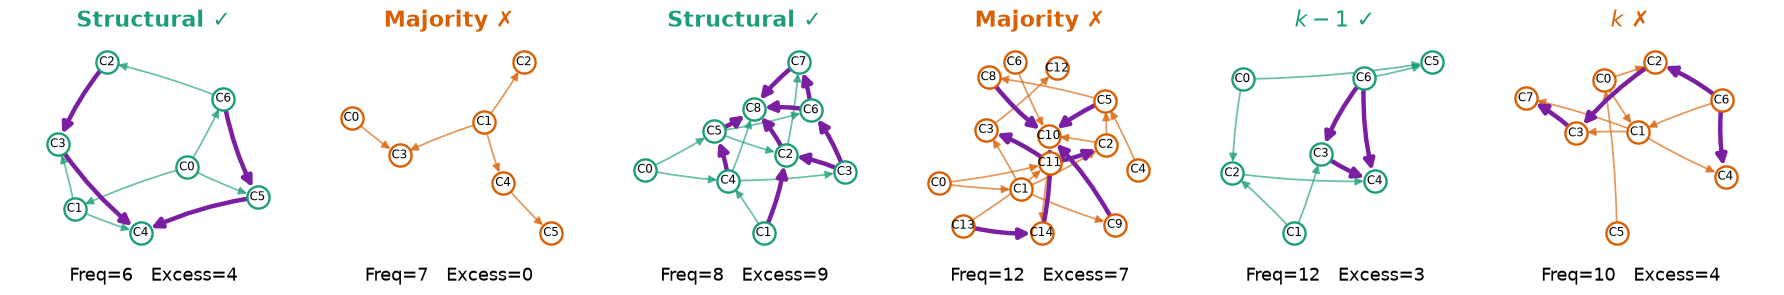

In [4]:
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
fig.subplots_adjust(left=0.015, right=0.995, top=0.86, bottom=0.20, wspace=0.03)
for number, (ax, graph, panel, row) in enumerate(
        zip(axes, graphs, panels.itertuples(), table.itertuples()), start=1):
    draw_panel(ax, graph, panel, row, number)

assets = root / "docs/assets"
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "figure1.png", bbox_inches="tight", dpi=155, facecolor="white")
fig.savefig(assets / "figure1.pdf", bbox_inches="tight", facecolor="white",
            metadata={"Title": "Representative shortcut graphs", "Creator": "Figure 1 notebook"})
plt.show()

On question 315, answer `41` has four excess edges across six traces. The seven traces for answer `1` form a tree. In the final pair, the score changes from $3/12$ for the correct answer at $k=40$ to $4/10$ for the wrong answer at $k=41$. These are static scores for the two displayed graphs. The archive also contains their smoothed selection scores in `w3_predictions.csv.gz`.